Matplotlib is building the font cache; this may take a moment.


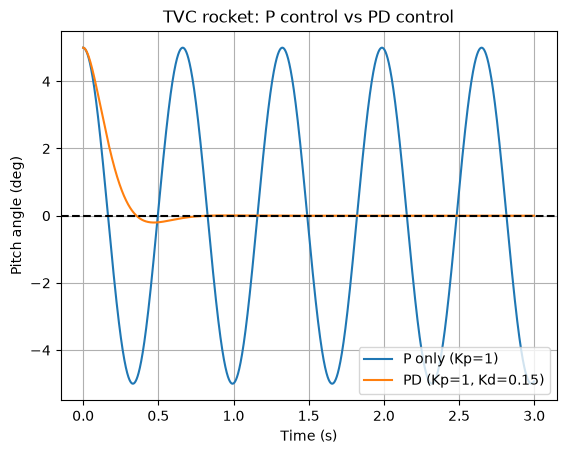

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

##rocket parameters

T = 15.0       # engine thrust in newtons
L = 0.3        # distance: gimbal - cg (m)
I = 0.05       #moment about cg (kg*m^2)
dt = 0.001    

t = np.arange(0, 3, dt)


##simulation

def simulate_tvc(Kp, Kd, theta0_deg=5.0):

    # store the rocket's state at every time step.
    theta = np.zeros_like(t)  # pitch angle in radians
    omega = np.zeros_like(t)  # angular velocity in rad/s
    delta = np.zeros_like(t)  # enginer gimbal command in radians

   #numpy expects radians
    theta[0] = np.radians(theta0_deg)

   
    for k in range(len(t) - 1):

        #error = target - current 
        error = 0.0 - theta[k]

        #commanded engine gimbal angle.
        delta[k] = Kp * error - Kd * omega[k]

        
        # Torque = T * L * sin(delta).
        # Angular acceleration = net torque / moment of inertia.
        alpha = T * L * np.sin(delta[k]) / I

        # EULER STEP 1:
        
        omega[k + 1] = omega[k] + alpha * dt

        # EULER STEP 2:
        
        #uses the NEW angular velocity, so it is semi-implicit Euler. stops the simulation from artificially adding energy to oscillating systems.
        theta[k + 1] = theta[k] + omega[k + 1] * dt

    # return tuple - simulated pitch angle, gimbal command history.
    return theta, delta


# --------------------------------------------------
# compare

# first: proportional control only.
# second: proportional + derivative control.
controllers = [
    (1.0, 0.0, "P only (Kp=1)"),
    (1.0, 0.15, "PD (Kp=1, Kd=0.15)")
]

for Kp, Kd, label in controllers:

    # run the sim
    theta, delta = simulate_tvc(Kp, Kd)

    # Convert pitch from radians to degrees for easier interpretation.
    plt.plot(t, np.degrees(theta), label=label)


#zero pitch = vertical 
plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Time (s)")
plt.ylabel("Pitch angle (deg)")
plt.title(" P control vs PD control")

plt.legend() 
plt.grid(True)  
plt.show()     
plt.plot(t, np.degrees(delta), label="Gimbal Command") #real gimbals are limited to around ±5°

p controller takes more time to settle down than pd.